# Axis 3 — Assisted tasks

**Owner: Member 3 · Branch: `axis-3` · Status: starting notebook, not a completed investigation.**

**Question:** For which tasks is AI used or expected to expand?

**Use for the sponsor:** Suggest a clearly bounded pilot task and document its potential limits.

The proposed sponsor is a DINUM team planning an AI coding-assistant pilot. These French survey respondents are not a sample of DINUM staff. Use the shared population and denominator rules before changing them.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the project root or its notebooks folder.")
sys.path.insert(0, str(ROOT))
from src.data import ensure_data, load_responses, load_schema
from src.population import prepare_population

ensure_data()
population = prepare_population(load_responses())
schema = load_schema()
print("2026 · France · coding as primary job · eligible respondents:", len(population))

2026 · France · coding as primary job · eligible respondents: 628


## 1. Check the fields and the answering population

In [2]:
fields = ['AIWorkCurrentlyUse', 'AIWorkExpectMore', 'AIWorkDoNotPlanToUse']
display(schema.loc[schema["column"].isin(fields), ["column", "question", "sub", "transformation"]])
display(pd.DataFrame({"answered": population[fields].notna().sum(),
                      "unanswered": population[fields].isna().sum()}))

,column,question,sub,transformation
108,AIWorkCurrentlyUse,Which parts of your workflow are you currently...,Currently use AI or AI agents for this,"Distinct selections, semicolon-separated"
109,AIWorkExpectMore,Which parts of your workflow are you currently...,Expect to use AI More or AI agents more for this,"Distinct selections, semicolon-separated"
111,AIWorkDoNotPlanToUse,Which parts of your workflow are you currently...,Do not use AI or AI agents for this and do not...,"Distinct selections, semicolon-separated"


,answered,unanswered
AIWorkCurrentlyUse,303,325
AIWorkExpectMore,260,368
AIWorkDoNotPlanToUse,246,382


## 2. A first descriptive view
This is a starting calculation. Record a factual observation and a separate question after inspecting it.

,answer,respondents,share_pct
0,Generating code in a familiar area,227,74.917492
1,"Debugging, troubleshooting, or refactoring code",214,70.627063
2,Writing or improving tests,203,66.996700
3,Generating code in an unfamiliar area,180,59.405941
4,"Writing documentation, comments, or knowledge ...",170,56.105611
5,Answering straightforward technical questions,168,55.445545
6,Answering complex or ambiguous technical quest...,159,52.475248
7,Architecture or technical design exploration,146,48.184818
8,Understanding or onboarding to a new codebase,141,46.534653
9,"Searching, summarizing, or interpreting intern...",125,41.254125


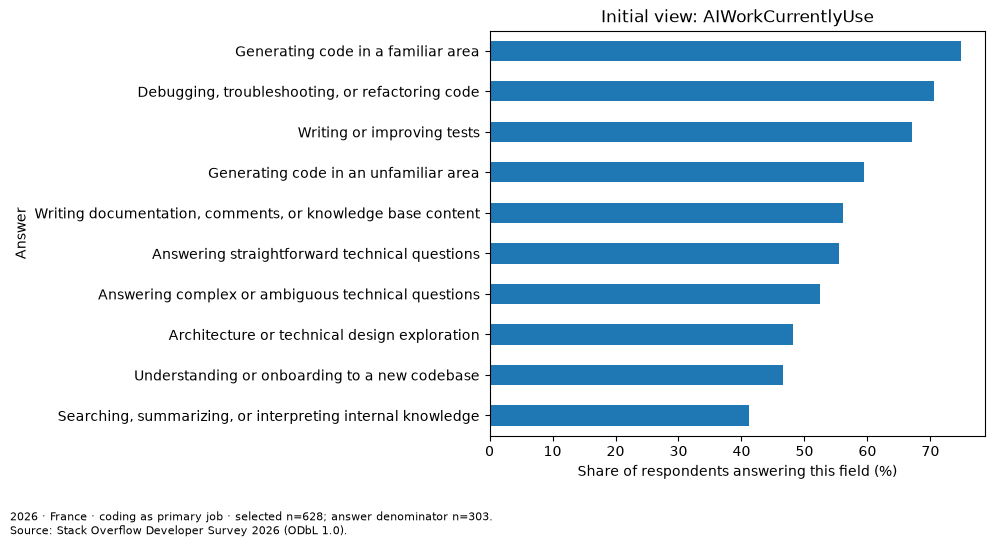

In [3]:
from src.analysis.axis_3 import summarise

column = 'AIWorkCurrentlyUse'
table, answered_n = summarise(population, column)
display(table.head(10))
ax = table.head(10).iloc[::-1].plot.barh(x="answer", y="share_pct", legend=False, figsize=(10, 5))
ax.set(title="Initial view: " + column, xlabel="Share of respondents answering this field (%)", ylabel="Answer")
plt.figtext(.01, -.08, f"2026 · France · coding as primary job · selected n={len(population)}; answer denominator n={answered_n}.\nSource: Stack Overflow Developer Survey 2026 (ODbL 1.0).", fontsize=8)
plt.tight_layout()
plt.show()

## 3. Work still to do — Member 3

1. Explore several useful views and write separate **I notice** / **I wonder** entries.
2. Formulate a testable hypothesis arising from those observations.
3. Read the questionnaire routing. Choose one defensible task comparison, show the denominator for each matrix column and check whether the result changes within a role or experience subgroup.
4. Explain what the evidence supports, what remains uncertain and what cannot be concluded.
5. Add one useful interaction and one clear view to `views/axis_3.py`, with calculations in `src/analysis/axis_3.py`.
6. Check the shared app and explain the code. Ask the assigned reviewer to read the PR.

Write your own analysis below this plan. The starter calculation is not a finished individual submission.